# Previsão do ICM com redes recorrentes

Este notebook cria um primeiro modelo de **regressão** para prever o valor do ICM de um trecho rodoviário no próximo mês observado. A implementação foi mantida simples para servir como ponto de partida dos experimentos do trabalho.

A entrada de cada exemplo é uma janela com os meses anteriores do mesmo trecho. Em cada passo temporal são fornecidos quatro atributos:

1. ICM normalizado;
2. indicador de que o ICM foi realmente observado (`1`) ou preenchido (`0`);
3. seno do mês do ano;
4. cosseno do mês do ano.

A variável-alvo é o ICM numérico do mês seguinte. Somente meses em que o alvo foi realmente medido geram exemplos.

## 1. Decisões iniciais e limitações

- A divisão entre treino, validação e teste é **cronológica**, usando o mês previsto.
- Não há embaralhamento antes da divisão temporal. O embaralhamento de lotes durante o ajuste é permitido porque ocorre somente dentro do treino.
- Ausências são preenchidas por propagação do último valor conhecido (`forward fill`), que utiliza apenas o passado. Quando não existe valor anterior, usa-se a mediana calculada somente no período de treino.
- A normalização também é ajustada somente com dados do período de treino.
- A avaliação abaixo representa uma previsão *rolling one-step-ahead*: ao prever um mês, observações reais de meses anteriores podem ser utilizadas.
- O dataset consolidado possui apenas uma variável física temporal, o ICM. A máscara de ausência e o calendário tornam a entrada tecnicamente multivariada, mas posteriormente vale avaliar a inclusão de ICC e ICP defasados.
- O processo atual de consolidação corrigiu algumas leituras usando meses vizinhos, inclusive posteriores. Isso deve ser registrado como possível fonte de vazamento e analisado antes do experimento final.

In [4]:
# ==========================================================================
# BLOCO 1 — Preparação do ambiente: instala/importa bibliotecas e fixa sementes.
# ==========================================================================

# Caso esteja executando no Google Colab e as bibliotecas não estejam instaladas,
# remova o comentário da linha seguinte e execute esta célula uma vez.
%pip install tensorflow pandas numpy matplotlib scikit-learn

# Path facilita trabalhar com caminhos de arquivos em diferentes sistemas.
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf

# Métricas usadas para avaliar a qualidade das previsões.
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Normalizador: aprende mínimos e máximos do período de treino.
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
# Camadas que compõem as redes neurais recorrentes.
from tensorflow.keras.layers import Dense, Dropout, GRU, Input, LSTM, SimpleRNN
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam

# Sementes fixas ajudam a reproduzir os resultados.
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)
tf.random.set_seed(SEMENTE)

## 2. Configurações

Todos os valores que provavelmente serão ajustados nos próximos experimentos estão reunidos abaixo. Inicialmente será usada uma `SimpleRNN`, como no exemplo fornecido. Para testar as outras redes, basta trocar `TIPO_REDE` por `GRU` ou `LSTM`.

In [5]:
# ==========================================================================
# BLOCO 2 — Configurações gerais do projeto.
# ==========================================================================

# Caminho do CSV a partir da RAIZ do projeto.
# Organização recomendada:
# meu_projeto/
# ├── treinamento_modelo_comentado_projeto.ipynb
# └── dataset/
#     └── dataset_icm.csv
# Se o nome/local do CSV mudar, altere somente esta variável.
CAMINHO_DADOS = Path('dataset/dataset_icm.csv')

# Cada exemplo utiliza os seis meses anteriores para prever o mês seguinte.
TAMANHO_JANELA = 6
# Quantidade mínima de meses com ICM realmente medido na janela.
MINIMO_OBSERVACOES = 3

# Separação cronológica dos meses-alvo disponíveis.
PROPORCAO_TREINO = 0.70
PROPORCAO_VALIDACAO = 0.15


## 3. Leitura e inspeção dos dados

O CSV será buscado **dentro da pasta do projeto**, preferencialmente em `dataset/dataset_icm.csv`. A célula também atende ao Colab quando o projeto estiver numa subpasta de `/content` ou quando o CSV estiver ao lado do notebook. Não é necessário alterar o caminho para cada execução, desde que a estrutura do projeto seja mantida.

**Observação sobre Google Colab:** abrir um notebook do GitHub ou do Drive não transfere automaticamente os demais arquivos do projeto para o ambiente do Colab. É necessário clonar/copiar a pasta do projeto para `/content`, ou montá-la no Drive e ajustar a raiz de busca, antes de executar a leitura.


In [7]:
# ==========================================================================
# BLOCO 3 — Localização do dataset e leitura do CSV.
# ==========================================================================

# Path permite localizar o CSV tanto localmente quanto no ambiente do Colab.
from pathlib import Path

# Pastas-raiz onde o projeto pode estar sendo executado.
# 1) Pasta atual: quando o notebook é executado a partir da raiz do projeto.
# 2) /content: diretório inicial padrão do Google Colab.
# 3) Subpastas de /content: quando o projeto foi clonado ou copiado para lá.
raizes = [Path.cwd(), Path('/content')]
if Path('/content').is_dir():
    raizes.extend(p for p in Path('/content').iterdir() if p.is_dir())

# Caminhos possíveis, sem modificar a estrutura de dados original.
# Também aceita o CSV diretamente na raiz do projeto.
candidatos = []
for raiz in raizes:
    candidatos.append(raiz / CAMINHO_DADOS)
    candidatos.append(raiz / CAMINHO_DADOS.name)

# Remove caminhos repetidos mantendo a ordem de preferência.
candidatos = list(dict.fromkeys(p.resolve() for p in candidatos))

# Descobre quais arquivos realmente existem.
encontrados = [p for p in candidatos if p.is_file()]
if not encontrados:
    raise FileNotFoundError(
        'Dataset não encontrado. Coloque dataset_icm.csv na pasta dataset/ '
        'da raiz do projeto. No Colab, copie/clone a pasta do projeto para '
        '/content antes de executar esta célula. Caminhos verificados:\n' +
        '\n'.join(str(p) for p in candidatos)
    )

# Se houver cópias em locais diferentes, avisa para evitar usar a base errada.
if len(encontrados) > 1:
    print('ATENÇÃO: mais de uma cópia do dataset foi encontrada:')
    for p in encontrados:
        print('  -', p)
    print('Utilizando a primeira da lista. Se necessário, altere CAMINHO_DADOS.')

caminho_efetivo = encontrados[0]
print('Carregando dataset de:', caminho_efetivo)

# Convenções do CSV original: separador de colunas ';' e decimal ','.
# utf-8-sig também aceita arquivo UTF-8 que possua BOM no início.
dados = pd.read_csv(
    caminho_efetivo,
    sep=';',
    decimal=',',
    encoding='utf-8-sig'
)

# Identificadores usados para reconhecer cada trecho rodoviário.
COLUNAS_ID = ['uf', 'rodovia', 'km_inicial', 'km_final']

# Identifica as colunas mensais com nomes no formato AAAA-MM.
colunas_meses = [
    coluna for coluna in dados.columns
    if len(coluna) == 7 and coluna[4] == '-'
]
if not colunas_meses:
    raise ValueError('Não foram encontradas colunas mensais no padrão AAAA-MM.')

# Transforma os nomes dos meses em períodos comparáveis cronologicamente.
meses = pd.PeriodIndex(colunas_meses, freq='M')

# Resumo para confirmar que o arquivo certo foi lido.
print(f'Trechos: {len(dados):,}'.replace(',', '.'))
print(f'Meses no arquivo: {len(colunas_meses)} ({meses.min()} a {meses.max()})')
print(f'Preenchimento da matriz: {dados[colunas_meses].notna().mean().mean():.2%}')
dados.head()


Trechos: 28.943
Meses no arquivo: 70 (2020-11 a 2026-08)
Preenchimento da matriz: 41.95%


,uf,rodovia,km_inicial,km_final,2020-11,2020-12,2021-01,2021-02,2021-03,2021-04,...,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08
0,AC,BR-307,107,108,22.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AC,BR-307,108,109,22.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AC,BR-307,109,110,26.5,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AC,BR-307,110,111,22.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AC,BR-307,111,112,22.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Separação cronológica

A separação é definida antes da normalização e da construção definitiva dos exemplos. Consideramos apenas meses que possuem algum alvo observado e que têm meses anteriores suficientes para formar uma janela. O conjunto de teste permanece intocado durante a escolha do modelo.

In [8]:
# ==========================================================================
# BLOCO 4 — Divisão temporal: separa os MESES-ALVO em treino, validação e teste, em ordem.
# ==========================================================================

# Matriz: linhas = trechos rodoviários; colunas = meses.
valores_originais = dados[colunas_meses].to_numpy(dtype=np.float32)
# 1 identifica ICM medido; 0 identifica valor ausente (NaN).
mascara_observado = (~np.isnan(valores_originais)).astype(np.float32)

# Meses que podem ser alvos: têm ao menos uma leitura e uma janela anterior completa.
# Descarta meses iniciais sem seis meses anteriores e meses sem nenhum alvo medido.
meses_alvo_disponiveis = [
    meses[posicao]
    for posicao in range(TAMANHO_JANELA, len(meses))
    if mascara_observado[:, posicao].sum() > 0
]

# Total de meses elegíveis para servir como mês a prever.
n_meses = len(meses_alvo_disponiveis)
# Quantos meses-alvo ficarão para o treino.
n_treino = int(n_meses * PROPORCAO_TREINO)
# Reserva ao menos um mês para validação.
n_validacao = max(1, int(n_meses * PROPORCAO_VALIDACAO))

# Garante ao menos um mês na validação e no teste.
# Ajuste defensivo para manter um mês no conjunto de teste.
if n_treino + n_validacao >= n_meses:
# Quantos meses-alvo ficarão para o treino.
    n_treino = n_meses - 2
# Reserva ao menos um mês para validação.
    n_validacao = 1

# Recortes consecutivos: os meses de teste são posteriores aos de validação.
meses_treino = meses_alvo_disponiveis[:n_treino]
meses_validacao = meses_alvo_disponiveis[n_treino:n_treino + n_validacao]
meses_teste = meses_alvo_disponiveis[n_treino + n_validacao:]

print(f'Treino:     {meses_treino[0]} a {meses_treino[-1]} ({len(meses_treino)} meses-alvo)')
print(f'Validação:  {meses_validacao[0]} a {meses_validacao[-1]} ({len(meses_validacao)} meses-alvo)')
print(f'Teste:      {meses_teste[0]} a {meses_teste[-1]} ({len(meses_teste)} meses-alvo)')

Treino:     2021-06 a 2025-05 (33 meses-alvo)
Validação:  2025-06 a 2025-12 (7 meses-alvo)
Teste:      2026-01 a 2026-08 (8 meses-alvo)


## 5. Tratamento de ausentes e normalização

O `forward fill` propaga somente informações passadas. A mediana e os limites do `MinMaxScaler` são estimados exclusivamente com meses pertencentes ao período de treino.

In [9]:
# ==========================================================================
# BLOCO 5 — Imputação e normalização: aprende estatísticas apenas no treino e codifica a época do ano.
# ==========================================================================

# Usa o último mês do treino como limite para calcular estatísticas.
ultimo_mes_treino = meses_treino[-1]
# Máscara de colunas com datas até o fim do treino.
posicoes_periodo_treino = np.array([mes <= ultimo_mes_treino for mes in meses])
# Considera todos os trechos, porém só meses do período de treino.
valores_periodo_treino = valores_originais[:, posicoes_periodo_treino]
# Remove NaN apenas da amostra usada nas estatísticas.
valores_observados_treino = valores_periodo_treino[~np.isnan(valores_periodo_treino)]

# Valor de preenchimento quando não existe medição anterior no mesmo trecho.
mediana_treino = float(np.median(valores_observados_treino))

# Propaga o último ICM conhecido de cada trecho apenas para a direita (passado -> futuro).
# O ffill copia para o futuro a última medição observada em cada linha.
valores_preenchidos = (
    pd.DataFrame(valores_originais)
    .ffill(axis=1)
    .fillna(mediana_treino)
    .to_numpy(dtype=np.float32)
)

# Aprende mínimo e máximo exclusivamente com medições reais do treino.
scaler = MinMaxScaler()
# fit APRENDE a escala; transform APLICA a mesma escala ao conjunto todo.
scaler.fit(valores_observados_treino.reshape(-1, 1))
# reshape(-1, 1) cria uma coluna para o scaler processar.
valores_normalizados = scaler.transform(valores_preenchidos.reshape(-1, 1))
valores_normalizados = valores_normalizados.reshape(valores_preenchidos.shape).astype(np.float32)

# Codificação cíclica: dezembro e janeiro ficam próximos na representação.
# Extrai mês numérico: janeiro=1, ..., dezembro=12.
numero_mes = np.array([mes.month for mes in meses], dtype=np.float32)
# Ângulo do mês no ciclo anual: 2π*mês/12; seno e cosseno preservam a vizinhança entre dez. e jan.
mes_seno = np.sin(2 * np.pi * numero_mes / 12).astype(np.float32)
mes_cosseno = np.cos(2 * np.pi * numero_mes / 12).astype(np.float32)

print(f'Mediana calculada no treino: {mediana_treino:.2f}')
print(f'Faixa aprendida pelo scaler: {scaler.data_min_[0]:.2f} a {scaler.data_max_[0]:.2f}')

Mediana calculada no treino: 22.50
Faixa aprendida pelo scaler: 0.00 a 100.00


## 6. Construção das janelas temporais

Cada trecho pode gerar vários exemplos, um para cada mês-alvo observado. Janelas com poucas medições reais são descartadas. O valor preenchido continua acompanhado da máscara, permitindo que a rede diferencie medição de imputação.

In [10]:
# ==========================================================================
# BLOCO 6 — Janelas: transforma o histórico em entradas X, alvos y e informações auxiliares.
# ==========================================================================

# Esta função será aplicada separadamente às listas de meses-alvo de cada partição.
def construir_particao(meses_alvo):
    blocos_x = []
    blocos_y = []
    blocos_baseline = []
    blocos_linhas = []
    blocos_meses = []

    for mes_alvo in meses_alvo:
        posicao = meses.get_loc(mes_alvo)
        inicio = posicao - TAMANHO_JANELA
        fim = posicao

        alvo_observado = mascara_observado[:, posicao] == 1
        observacoes_na_janela = mascara_observado[:, inicio:fim].sum(axis=1)
        linhas_validas = np.flatnonzero(
            alvo_observado & (observacoes_na_janela >= MINIMO_OBSERVACOES)
        )

        if len(linhas_validas) == 0:
            continue

        icm = valores_normalizados[linhas_validas, inicio:fim]
        mascara = mascara_observado[linhas_validas, inicio:fim]
        seno = np.broadcast_to(mes_seno[inicio:fim], icm.shape)
        cosseno = np.broadcast_to(mes_cosseno[inicio:fim], icm.shape)

        # Formato esperado pela RNN: [exemplos, passos temporais, atributos].
        bloco_x = np.stack([icm, mascara, seno, cosseno], axis=-1).astype(np.float32)
        alvo_real = valores_originais[linhas_validas, posicao]
        alvo_normalizado = scaler.transform(alvo_real.reshape(-1, 1)).ravel().astype(np.float32)

        blocos_x.append(bloco_x)
        blocos_y.append(alvo_normalizado)
        # Baseline: o próximo ICM será igual ao último valor disponível no passado.
        blocos_baseline.append(valores_preenchidos[linhas_validas, posicao - 1])
        blocos_linhas.append(linhas_validas)
        blocos_meses.append(np.full(len(linhas_validas), str(mes_alvo), dtype='<U7'))

    return {
        'X': np.concatenate(blocos_x),
        'y': np.concatenate(blocos_y),
        'baseline': np.concatenate(blocos_baseline),
        'linha': np.concatenate(blocos_linhas),
        'mes_alvo': np.concatenate(blocos_meses),
    }

# Cria os exemplos dos três conjuntos respeitando os meses-alvo definidos acima.
treino = construir_particao(meses_treino)
validacao = construir_particao(meses_validacao)
teste = construir_particao(meses_teste)

for nome, particao in [('Treino', treino), ('Validação', validacao), ('Teste', teste)]:
    print(f'{nome:10s}: X={particao["X"].shape} | y={particao["y"].shape}')

Treino    : X=(438352, 6, 4) | y=(438352,)
Validação : X=(85990, 6, 4) | y=(85990,)
Teste     : X=(130795, 6, 4) | y=(130795,)


## 7. Baseline de persistência

Antes da rede neural, avaliamos uma regra simples: repetir como previsão o último ICM conhecido. A rede só representa ganho prático se superar referências simples sob o mesmo conjunto de teste.

In [11]:
# ==========================================================================
# BLOCO 7 — Baseline: previsão por persistência e métricas em escala original.
# ==========================================================================

# Desfaz a normalização e retorna os valores em pontos de ICM.
def voltar_escala(y_normalizado):
    return scaler.inverse_transform(np.asarray(y_normalizado).reshape(-1, 1)).ravel()

# MAE mede erro médio absoluto; RMSE penaliza mais erros grandes; R² mede ajuste relativo.
def calcular_metricas(y_real, y_previsto):
    return {
        'MAE': mean_absolute_error(y_real, y_previsto),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_previsto)),
        'R²': r2_score(y_real, y_previsto),
    }

# Converte o valor esperado de teste para a escala de ICM original.
y_teste_real = voltar_escala(teste['y'])
# Compara valores reais com a previsão do último ICM conhecido.
metricas_baseline = calcular_metricas(y_teste_real, teste['baseline'])
pd.DataFrame([metricas_baseline], index=['Persistência']).round(3)

,MAE,RMSE,R²
Persistência,7.187,10.302,0.559


## 8. Construção do modelo recorrente

A camada de saída tem um neurônio com ativação linear porque o problema é de regressão. A função permite criar `SimpleRNN`, `GRU` ou `LSTM` com a mesma configuração, facilitando a comparação exigida no trabalho.

In [12]:
# ==========================================================================
# BLOCO 8 — Arquiteturas: cria SimpleRNN, GRU ou LSTM com parâmetros configuráveis.
# ==========================================================================

# Mapeia cada nome de arquitetura para sua classe Keras.
camadas = {
    "SimpleRNN": SimpleRNN,
    "LSTM": LSTM,
    "GRU": GRU
}

# Recebe rede e hiperparâmetros; devolve um modelo novo ainda não treinado.
def criar_modelo(tipo_rede, formato_entrada,
                 unidades, dropout, learning_rate):

    modelo = Sequential([
        Input(shape=formato_entrada),

        camadas[tipo_rede](
            unidades,
            return_sequences=False
        ),

        Dropout(dropout),

        Dense(1, activation='linear')
    ])

    modelo.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mse',
        metrics=['mae']
    )

    return modelo

#Optuna

In [13]:
# ==========================================================================
# OPTUNA — Instalação da biblioteca de otimização.
# ==========================================================================

# Instala a biblioteca que automatiza tentativas de hiperparâmetros no Colab.
%pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.9 MB/s eta 0:00:00


#Otimizador de rede

In [14]:
# ==========================================================================
# OPTUNA — Busca rápida: amostra 25% do treino e avalia configurações pela validação.
# ==========================================================================

import optuna
import numpy as np
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# Utiliza 25% do treinamento durante a otimização
# Busca mais rápida: 25% das amostras de treino, mas validação inteira.
FRACAO_TREINO_OPTUNA = 0.25

# Seleciona amostras distribuídas ao longo do treino.
# Reproduzível e sem utilizar dados do teste.
# Gerador aleatório com semente fixa para selecionar os mesmos exemplos.
rng = np.random.default_rng(SEMENTE)

# Calcula quantidade aproximada de janelas a usar na busca.
quantidade = int(
    len(treino["X"]) * FRACAO_TREINO_OPTUNA
)

# Seleção sem reposição; ordenar os índices mantém a ordem relativa.
indices = np.sort(
    rng.choice(
        len(treino["X"]),
        size=quantidade,
        replace=False
    )
)

# Subconjunto do treino; NÃO inclui validação nem teste.
X_optuna = treino["X"][indices]
y_optuna = treino["y"][indices]

print("Amostras para Optuna:", len(X_optuna))


# Cria um estudo Optuna específico para cada arquitetura.
def otimizar_rede(tipo_rede):

    def objective(trial):

        # Menos combinações de neurônios
        unidades = trial.suggest_categorical(
            "unidades", [16, 32, 64]
        )

        # Intervalo mais restrito de Dropout
        dropout = trial.suggest_float(
            "dropout", 0.1, 0.3
        )

        # Taxa de aprendizado
        learning_rate = trial.suggest_float(
            "learning_rate",
            0.0005,
            0.003,
            log=True
        )

        # Batches maiores para acelerar
        batch_size = trial.suggest_categorical(
            "batch_size", [128, 256, 512]
        )

        # Libera recursos entre tentativas
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEMENTE)

        modelo = criar_modelo(
            tipo_rede=tipo_rede,
            formato_entrada=X_optuna.shape[1:],
            unidades=unidades,
            dropout=dropout,
            learning_rate=learning_rate
        )

        # Interrompe tentativas pouco promissoras
        parada = EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )

        historico = modelo.fit(
            X_optuna,
            y_optuna,

            # Mantém a validação original
            validation_data=(
                validacao["X"],
                validacao["y"]
            ),

            # Limita a duração da tentativa
            epochs=15,

            batch_size=batch_size,

            callbacks=[parada],

            shuffle=False,
            verbose=0
        )

        return min(historico.history["val_loss"])

    estudo = optuna.create_study(
        direction="minimize",
        sampler=optuna.samplers.TPESampler(
            seed=SEMENTE
        )
    )

    # Reduz de 30 para 10 tentativas
    estudo.optimize(
        objective,
        n_trials=10
    )

    return estudo

Amostras para Optuna: 109588


#Encontrar melhores parâmetros

In [15]:
# ==========================================================================
# OPTUNA — Executa a busca para as três arquiteturas e guarda os melhores parâmetros.
# ==========================================================================

# Dicionário: nome da arquitetura -> melhores parâmetros de sua busca.
melhores_parametros = {}

# Otimiza as três redes independentemente.
for rede in ["SimpleRNN", "LSTM", "GRU"]:

    print(f"Otimizando {rede}")

    estudo = otimizar_rede(rede)

    melhores_parametros[rede] = estudo.best_params

    print(estudo.best_params)

[I 2026-10-15 12:27:45,806] A new study created in memory with name: no-name-a5d27d22-481f-4f3f-a4bb-a77ce097e69f


Otimizando SimpleRNN


[I 2026-10-15 12:28:08,490] Trial 0 finished with value: 0.008357449434697628 and parameters: {'unidades': 32, 'dropout': 0.2197316968394073, 'learning_rate': 0.0006612658646612707, 'batch_size': 512}. Best is trial 0 with value: 0.008357449434697628.
[I 2026-10-15 12:28:28,997] Trial 1 finished with value: 0.007405861280858517 and parameters: {'unidades': 32, 'dropout': 0.2939819704323988, 'learning_rate': 0.002221960254254887, 'batch_size': 128}. Best is trial 1 with value: 0.007405861280858517.
[I 2026-10-15 12:28:41,941] Trial 2 finished with value: 0.01671457849442959 and parameters: {'unidades': 32, 'dropout': 0.15824582803960838, 'learning_rate': 0.0014965254242886722, 'batch_size': 512}. Best is trial 1 with value: 0.007405861280858517.
[I 2026-10-15 12:29:22,549] Trial 3 finished with value: 0.006710780318826437 and parameters: {'unidades': 32, 'dropout': 0.2028468876827223, 'learning_rate': 0.0014453004631242248, 'batch_size': 256}. Best is trial 3 with value: 0.0067107803188

{'unidades': 32, 'dropout': 0.2028468876827223, 'learning_rate': 0.0014453004631242248, 'batch_size': 256}
Otimizando LSTM


[I 2026-10-15 12:33:38,563] Trial 0 finished with value: 0.009920435026288033 and parameters: {'unidades': 32, 'dropout': 0.2197316968394073, 'learning_rate': 0.0006612658646612707, 'batch_size': 512}. Best is trial 0 with value: 0.009920435026288033.
[I 2026-10-15 12:34:26,996] Trial 1 finished with value: 0.006839219015091658 and parameters: {'unidades': 32, 'dropout': 0.2939819704323988, 'learning_rate': 0.002221960254254887, 'batch_size': 128}. Best is trial 1 with value: 0.006839219015091658.
[I 2026-10-15 12:35:23,697] Trial 2 finished with value: 0.007144922856241465 and parameters: {'unidades': 32, 'dropout': 0.15824582803960838, 'learning_rate': 0.0014965254242886722, 'batch_size': 512}. Best is trial 1 with value: 0.006839219015091658.
[I 2026-10-15 12:36:24,000] Trial 3 finished with value: 0.0064926473423838615 and parameters: {'unidades': 32, 'dropout': 0.2028468876827223, 'learning_rate': 0.0014453004631242248, 'batch_size': 256}. Best is trial 3 with value: 0.00649264734

{'unidades': 64, 'dropout': 0.2550265646722229, 'learning_rate': 0.0026917968492498018, 'batch_size': 512}
Otimizando GRU


[I 2026-10-15 12:45:37,082] Trial 0 finished with value: 0.015625158324837685 and parameters: {'unidades': 32, 'dropout': 0.2197316968394073, 'learning_rate': 0.0006612658646612707, 'batch_size': 512}. Best is trial 0 with value: 0.015625158324837685.
[I 2026-10-15 12:46:46,760] Trial 1 finished with value: 0.006822698283940554 and parameters: {'unidades': 32, 'dropout': 0.2939819704323988, 'learning_rate': 0.002221960254254887, 'batch_size': 128}. Best is trial 1 with value: 0.006822698283940554.
[I 2026-10-15 12:47:03,853] Trial 2 finished with value: 0.035860393196344376 and parameters: {'unidades': 32, 'dropout': 0.15824582803960838, 'learning_rate': 0.0014965254242886722, 'batch_size': 512}. Best is trial 1 with value: 0.006822698283940554.
[I 2026-10-15 12:47:57,761] Trial 3 finished with value: 0.006673377938568592 and parameters: {'unidades': 32, 'dropout': 0.2028468876827223, 'learning_rate': 0.0014453004631242248, 'batch_size': 256}. Best is trial 3 with value: 0.006673377938

{'unidades': 32, 'dropout': 0.2818640804157564, 'learning_rate': 0.0007949502872202297, 'batch_size': 128}


## 9. Treinamento

A parada antecipada monitora exclusivamente a perda de validação e recupera os pesos da melhor época. O teste não participa do treinamento nem da escolha do ponto de parada.

In [16]:
# ==========================================================================
# BLOCO 9 — Treinamento final: treina cada rede com todo o conjunto de treino.
# ==========================================================================

# Armazena modelos já treinados.
modelos = {}
# Armazena loss/val_loss de cada época para gráficos.
historicos = {}

for tipo_rede in ["SimpleRNN", "LSTM", "GRU"]:

    print(f"\nTreinando: {tipo_rede}")

    params = melhores_parametros[tipo_rede]

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMENTE)

    modelo = criar_modelo(
        tipo_rede=tipo_rede,
        formato_entrada=treino['X'].shape[1:],
        unidades=params["unidades"],
        dropout=params["dropout"],
        learning_rate=params["learning_rate"]
    )

    parada_antecipada = EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    )

    historico = modelo.fit(
        treino['X'],
        treino['y'],
        validation_data=(
            validacao['X'],
            validacao['y']
        ),
        epochs=100,
        batch_size=params["batch_size"],
        callbacks=[parada_antecipada],
        shuffle=False,
        verbose=1
    )

    modelos[tipo_rede] = modelo
    historicos[tipo_rede] = historico


Treinando: SimpleRNN
Epoch 1/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0250 - mae: 0.1114 - val_loss: 0.0078 - val_mae: 0.0678
Epoch 2/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0140 - mae: 0.0839 - val_loss: 0.0069 - val_mae: 0.0584
Epoch 3/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0134 - mae: 0.0815 - val_loss: 0.0070 - val_mae: 0.0601
Epoch 4/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0131 - mae: 0.0802 - val_loss: 0.0070 - val_mae: 0.0603
Epoch 5/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0130 - mae: 0.0797 - val_loss: 0.0069 - val_mae: 0.0592
Epoch 6/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0129 - mae: 0.0794 - val_loss: 0.0068 - val_mae: 0.0586
Epoch 7/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0129 - mae: 0.0793 - val_loss: 0.0068 - val_mae: 0.0598
Epoch 8/100
1713/1713 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - loss: 0.0129 - mae: 0.0792 - val_loss: 0.0069 - val_mae: 0.0609
Epoch 9/10

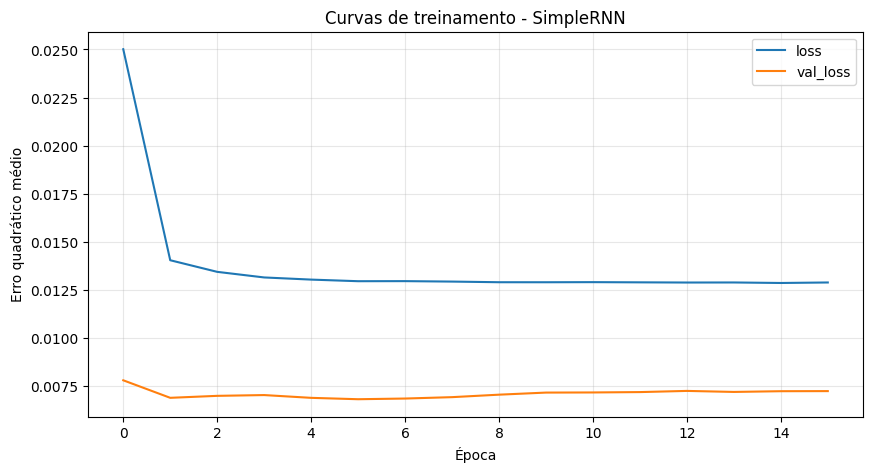

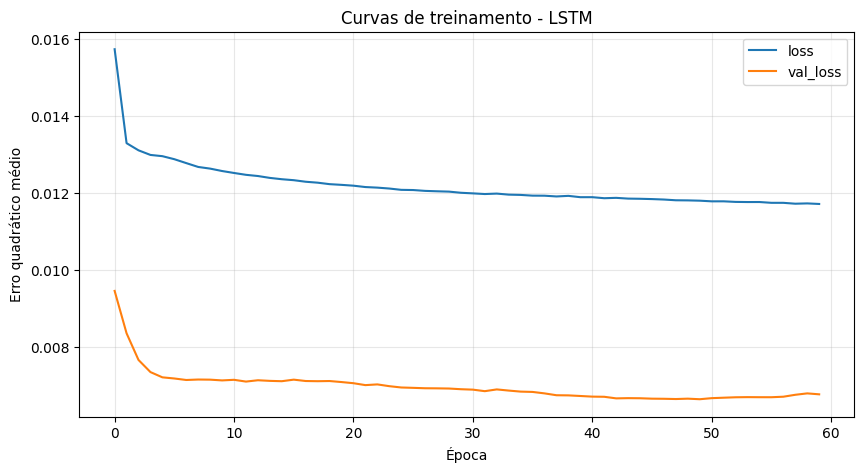

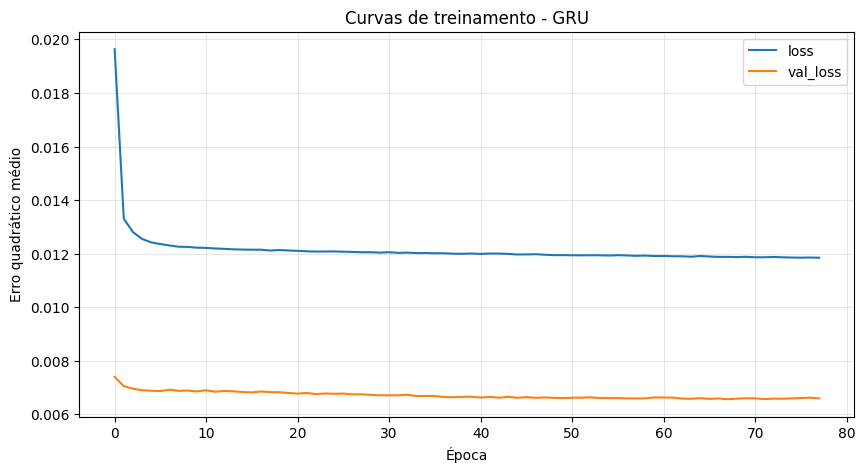

In [17]:
# ==========================================================================
# BLOCO 9 — Visualização: plota as curvas de erro de treino e validação.
# ==========================================================================

# Plota separadamente cada arquitetura treinada.
for tipo_rede, historico in historicos.items():

    historico_df = pd.DataFrame(historico.history)

    ax = historico_df[['loss', 'val_loss']].plot(
        figsize=(10, 5)
    )

    ax.set_title(
        f'Curvas de treinamento - {tipo_rede}'
    )

    ax.set_xlabel('Época')
    ax.set_ylabel('Erro quadrático médio')
    ax.grid(alpha=0.3)

    plt.show()

## 10. Avaliação final no teste

As previsões são devolvidas à escala original do ICM. MAE e RMSE ficam, portanto, expressos em pontos de ICM. O conjunto de teste deve ser avaliado apenas depois de escolhida a configuração final com a validação.

In [18]:
# ==========================================================================
# BLOCO 10 — Avaliação: prevê no teste e compara com a baseline.
# ==========================================================================

# Guardará a previsão de cada rede na escala original do ICM.
previsoes_teste = {}

# Inicia a comparação com a baseline de persistência.
resultados = {
    "Persistência": metricas_baseline
}

# Executa inferência somente após concluir a escolha de parâmetros.
for tipo_rede, modelo in modelos.items():

    params = melhores_parametros[tipo_rede]

    previsao_normalizada = modelo.predict(
        teste['X'],
        batch_size=params["batch_size"]
    ).ravel()

    previsao = voltar_escala(previsao_normalizada)

    previsoes_teste[tipo_rede] = previsao

    resultados[tipo_rede] = calcular_metricas(
        y_teste_real,
        previsao
    )

# Linhas: métodos; colunas: métricas para comparar desempenho.
comparacao = pd.DataFrame(resultados).T

display(comparacao.round(3))

511/511 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
256/256 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


,MAE,RMSE,R²
Persistência,7.187,10.302,0.559
SimpleRNN,7.300,9.633,0.614
LSTM,6.895,9.312,0.640
GRU,6.887,9.286,0.642


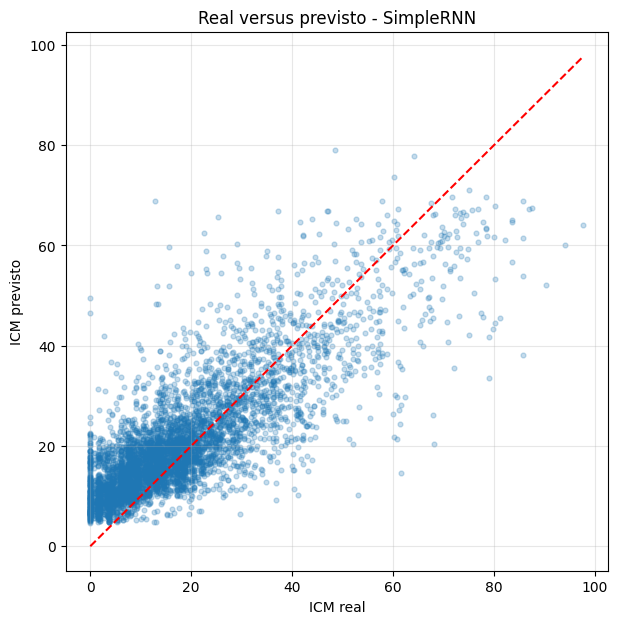

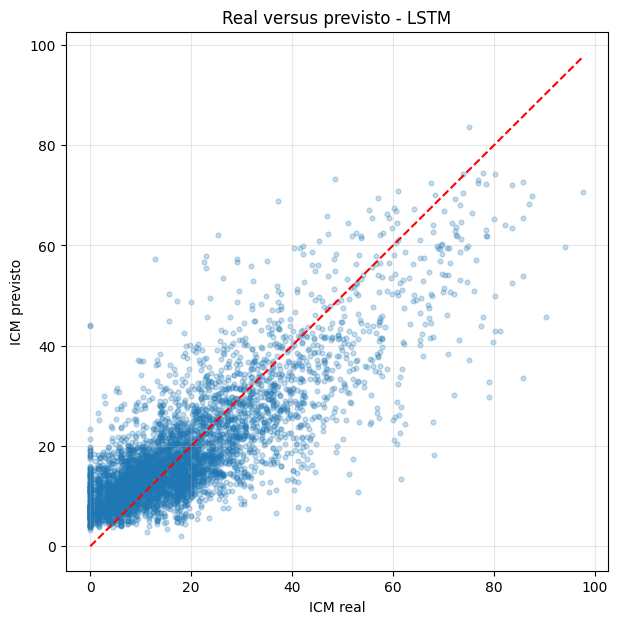

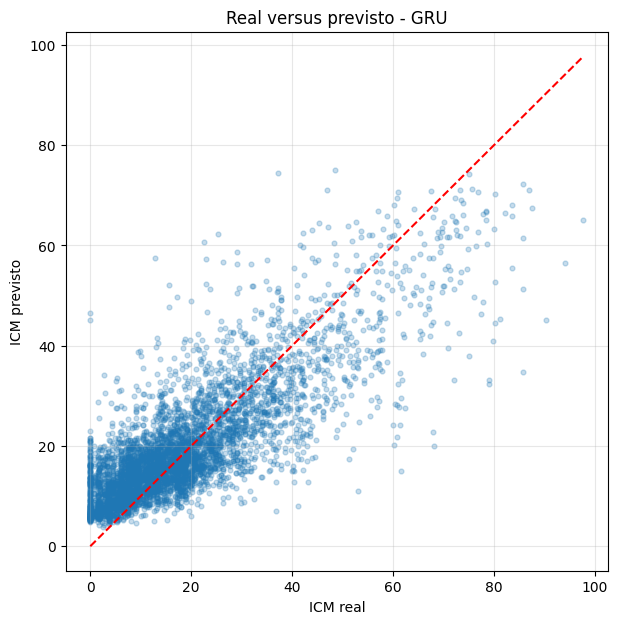

In [19]:
# ==========================================================================
# BLOCO 10 — Visualização: dispersão entre ICM real e previsto.
# ==========================================================================

rng = np.random.default_rng(SEMENTE)

# Limita a 5 mil pontos para o gráfico não ficar muito pesado.
quantidade_grafico = min(5000, len(y_teste_real))

# Seleciona sempre os mesmos exemplos visuais usando semente.
amostra = rng.choice(
    len(y_teste_real),
    size=quantidade_grafico,
    replace=False
)

for tipo_rede, previsao in previsoes_teste.items():

    plt.figure(figsize=(7, 7))

    plt.scatter(
        y_teste_real[amostra],
        previsao[amostra],
        alpha=0.25,
        s=12
    )

    limite_minimo = min(
        y_teste_real[amostra].min(),
        previsao[amostra].min()
    )

    limite_maximo = max(
        y_teste_real[amostra].max(),
        previsao[amostra].max()
    )

    plt.plot(
        [limite_minimo, limite_maximo],
        [limite_minimo, limite_maximo],
        'r--'
    )

    plt.xlabel('ICM real')
    plt.ylabel('ICM previsto')
    plt.title(f'Real versus previsto - {tipo_rede}')
    plt.grid(alpha=0.3)

    plt.show()

In [20]:
# ==========================================================================
# BLOCO 10 — Detalhamento: tabela com cada trecho, mês, previsão e erro.
# ==========================================================================

# Recupera metadados originais dos trechos correspondentes às janelas de teste.
resultado_teste = dados.loc[
    teste['linha'], COLUNAS_ID
].reset_index(drop=True).copy()

# Acrescenta mês que foi previsto, valor observado e baseline.
resultado_teste['mes_alvo'] = teste['mes_alvo']
resultado_teste['icm_real'] = y_teste_real
resultado_teste['icm_persistencia'] = teste['baseline']

# Para cada arquitetura, acrescenta previsão e erro absoluto por exemplo.
for tipo_rede, previsao in previsoes_teste.items():
    resultado_teste[f'previsto_{tipo_rede}'] = previsao
    resultado_teste[f'erro_{tipo_rede}'] = np.abs(
        y_teste_real - previsao
    )

# Mostra as dez primeiras linhas da tabela comparativa.
display(resultado_teste.head(10))

,uf,rodovia,km_inicial,km_final,mes_alvo,icm_real,icm_persistencia,previsto_SimpleRNN,erro_SimpleRNN,previsto_LSTM,erro_LSTM,previsto_GRU,erro_GRU
0,AC,BR-307,156,157,2026-01,19.000000,7.880000,11.807492,7.192508,11.706090,7.293910,13.184639,5.815361
1,AC,BR-307,157,158,2026-01,61.750004,35.750000,34.099110,27.650894,31.147123,30.602880,33.631481,28.118523
2,AC,BR-307,158,159,2026-01,47.380001,18.250000,22.736357,24.643644,23.263706,24.116295,24.605635,22.774366
3,AC,BR-307,159,160,2026-01,41.880001,23.750000,24.057442,17.822559,21.701227,20.178774,23.608418,18.271584
4,AC,BR-307,160,161,2026-01,72.000000,20.750000,23.653111,48.346889,23.265982,48.734016,24.460888,47.539112
5,AC,BR-307,161,162,2026-01,44.250000,22.379999,24.429832,19.820168,23.868832,20.381168,25.659758,18.590242
6,AC,BR-307,162,163,2026-01,38.380001,23.750000,27.843712,10.536289,27.659563,10.720438,29.553619,8.826382
7,AC,BR-307,163,164,2026-01,24.120001,20.879999,22.894722,1.225279,22.064510,2.055490,23.606941,0.513060
8,AC,BR-307,164,165,2026-01,16.379999,19.000000,20.360834,3.980835,18.803843,2.423843,20.650766,4.270767
9,AC,BR-307,165,166,2026-01,24.620001,19.000000,21.642067,2.977934,21.501877,3.118124,23.161558,1.458443


## 11. Próximos experimentos

Depois de validar este modelo inicial, os ajustes mais informativos são:

1. comparar janelas de 3, 6 e 12 meses;
2. comparar SimpleRNN, GRU e LSTM;
3. variar unidades recorrentes, taxa de aprendizado, dropout e batch size;
4. testar outros critérios para o número mínimo de observações na janela;
5. adicionar ICC e ICP históricos, verificando antes sua relação com o cálculo do ICM;
6. medir tempo de treinamento, tempo de inferência e número de parâmetros;
7. repetir a avaliação sem os levantamentos suspeitos ou copiados;
8. considerar uma avaliação adicional por rodovia para medir generalização espacial.

Durante a busca de hiperparâmetros, escolha configurações exclusivamente pela validação. O teste deve ser consultado uma única vez para a avaliação final.